# 07 — Brain 3D Reconstruction from Anonymized DICOM CT

This notebook reconstructs the intracranial soft-tissue envelope from the
`BRAIN_HR36F` series. It sorts slices using DICOM geometry, converts pixels to
Hounsfield units, performs conservative skull stripping, extracts and smooths
the surface, and exports interactive and reusable 3D files.

No source file is modified and no identifying metadata is displayed. Since the
study contains no manual brain mask, this is an algorithmic visualization mask,
not a validated clinical segmentation.

In [1]:
from pathlib import Path
import json, time

import matplotlib.pyplot as plt
import numpy as np
import pydicom
import plotly.graph_objects as go
import trimesh
from scipy import ndimage as ndi
from skimage import measure
from skimage.morphology import disk

STARTED = time.time()
DATASET_ROOT = Path(r"F:\csstdy\Single_Patient_Study")
OUTPUT_DIR = Path(r"F:\csstdy\outputs\07_3d_reconstruction\brain")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

XY_DOWNSAMPLE = 2
Z_DOWNSAMPLE = 1
SOFT_TISSUE_MIN_HU = -10.0
SOFT_TISSUE_MAX_HU = 120.0
MINIMUM_HEAD_DEPTH_MM = 7.0
INFERIOR_CROP_INDEX = 45
SMOOTHING_ITERATIONS = 15

assert DATASET_ROOT.exists(), f"Dataset not found: {DATASET_ROOT}"
print("Dataset:", DATASET_ROOT)
print("Output:", OUTPUT_DIR)

Dataset: F:\csstdy\Single_Patient_Study
Output: F:\csstdy\outputs\07_3d_reconstruction\brain


## Load and geometrically sort the soft-tissue CT series

Slice order is derived from `ImagePositionPatient` and
`ImageOrientationPatient`, rather than filenames.

In [2]:
series_dirs = sorted(path for path in DATASET_ROOT.rglob("BRAIN_HR36F") if path.is_dir())
if not series_dirs:
    raise FileNotFoundError("No BRAIN_HR36F directory found.")
SERIES_DIR = series_dirs[0]
datasets = [pydicom.dcmread(path, force=True) for path in sorted(SERIES_DIR.glob("*.dcm"))]
if len(datasets) < 3:
    raise RuntimeError("Too few slices for 3D reconstruction.")

first = datasets[0]
orientation = np.asarray(first.ImageOrientationPatient, dtype=float)
row_direction = orientation[:3]
column_direction = orientation[3:]
slice_normal = np.cross(row_direction, column_direction)
slice_normal /= np.linalg.norm(slice_normal)
locations = np.asarray([
    np.dot(np.asarray(ds.ImagePositionPatient, dtype=float), slice_normal) for ds in datasets
])
order = np.argsort(locations)
datasets = [datasets[index] for index in order]
locations = locations[order]

if len(np.unique(np.round(locations, 5))) != len(datasets):
    raise RuntimeError("Duplicate anatomical slice positions detected.")
differences = np.diff(locations)
slice_spacing = float(np.median(np.abs(differences)))
row_spacing, column_spacing = (float(value) for value in first.PixelSpacing)
rows, columns = int(first.Rows), int(first.Columns)
assert np.allclose(differences, np.median(differences), atol=1e-3)
assert all(int(ds.Rows) == rows and int(ds.Columns) == columns for ds in datasets)

print("Series:", SERIES_DIR.name)
print("Slices:", len(datasets), "| matrix:", (rows, columns))
print("Voxel spacing (slice, row, column) mm:", (slice_spacing, row_spacing, column_spacing))

Series: BRAIN_HR36F
Slices: 227 | matrix: (512, 512)
Voxel spacing (slice, row, column) mm: (0.75, 0.55574609375, 0.55574609375)


## Assemble the volume and derive the intracranial mask

In [3]:
volume_hu = np.empty((len(datasets), rows, columns), dtype=np.float32)
for index, ds in enumerate(datasets):
    volume_hu[index] = (
        ds.pixel_array.astype(np.float32) * float(getattr(ds, "RescaleSlope", 1.0))
        + float(getattr(ds, "RescaleIntercept", 0.0))
    )

working_hu = volume_hu[::Z_DOWNSAMPLE, ::XY_DOWNSAMPLE, ::XY_DOWNSAMPLE]
working_spacing = (
    slice_spacing * Z_DOWNSAMPLE,
    row_spacing * XY_DOWNSAMPLE,
    column_spacing * XY_DOWNSAMPLE,
)
smoothed_hu = ndi.gaussian_filter(working_hu, sigma=(0.5, 0.7, 0.7))


def largest_2d(mask):
    labels, count = ndi.label(mask)
    if not count:
        return np.zeros_like(mask, dtype=bool)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    return labels == sizes.argmax()


brain_mask = np.zeros_like(smoothed_hu, dtype=bool)
for z in range(len(smoothed_hu)):
    head = largest_2d(smoothed_hu[z] > -300)
    head = ndi.binary_fill_holes(ndi.binary_closing(head, structure=disk(4)))
    depth_mm = ndi.distance_transform_edt(head, sampling=working_spacing[1:])
    candidate = (
        (depth_mm >= MINIMUM_HEAD_DEPTH_MM)
        & (smoothed_hu[z] >= SOFT_TISSUE_MIN_HU)
        & (smoothed_hu[z] <= SOFT_TISSUE_MAX_HU)
    )
    candidate = ndi.binary_opening(candidate, structure=disk(1))
    candidate = ndi.binary_closing(candidate, structure=disk(2))
    brain_mask[z] = ndi.binary_fill_holes(largest_2d(candidate))

# Remove inferior face/upper-neck sections before 3D cleanup.
brain_mask[:INFERIOR_CROP_INDEX] = False
brain_mask = ndi.binary_opening(
    brain_mask, structure=ndi.generate_binary_structure(3, 1), iterations=1
)
brain_mask = ndi.binary_closing(
    brain_mask, structure=ndi.generate_binary_structure(3, 2), iterations=2
)
labels, _ = ndi.label(brain_mask, structure=ndi.generate_binary_structure(3, 2))
sizes = np.bincount(labels.ravel())
sizes[0] = 0
ordered = np.argsort(sizes)[::-1]
kept_components = [int(label) for label in ordered[:8] if sizes[label] >= 1000]
brain_mask = np.isin(labels, kept_components)
for z in range(len(brain_mask)):
    brain_mask[z] = ndi.binary_fill_holes(brain_mask[z])
brain_mask = ndi.binary_closing(
    brain_mask, structure=ndi.generate_binary_structure(3, 2), iterations=2
)
if not brain_mask.any():
    raise RuntimeError("Derived brain mask is empty.")

voxel_volume_mm3 = float(np.prod(working_spacing))
mask_volume_ml = float(brain_mask.sum() * voxel_volume_mm3 / 1000.0)
print("Working volume:", working_hu.shape)
print("Mask voxels:", f"{int(brain_mask.sum()):,}")
print("Approximate envelope volume:", f"{mask_volume_ml:.1f} mL")

Working volume: (227, 256, 256)
Mask voxels: 1,321,986
Approximate envelope volume: 1224.9 mL


## Verify mask alignment

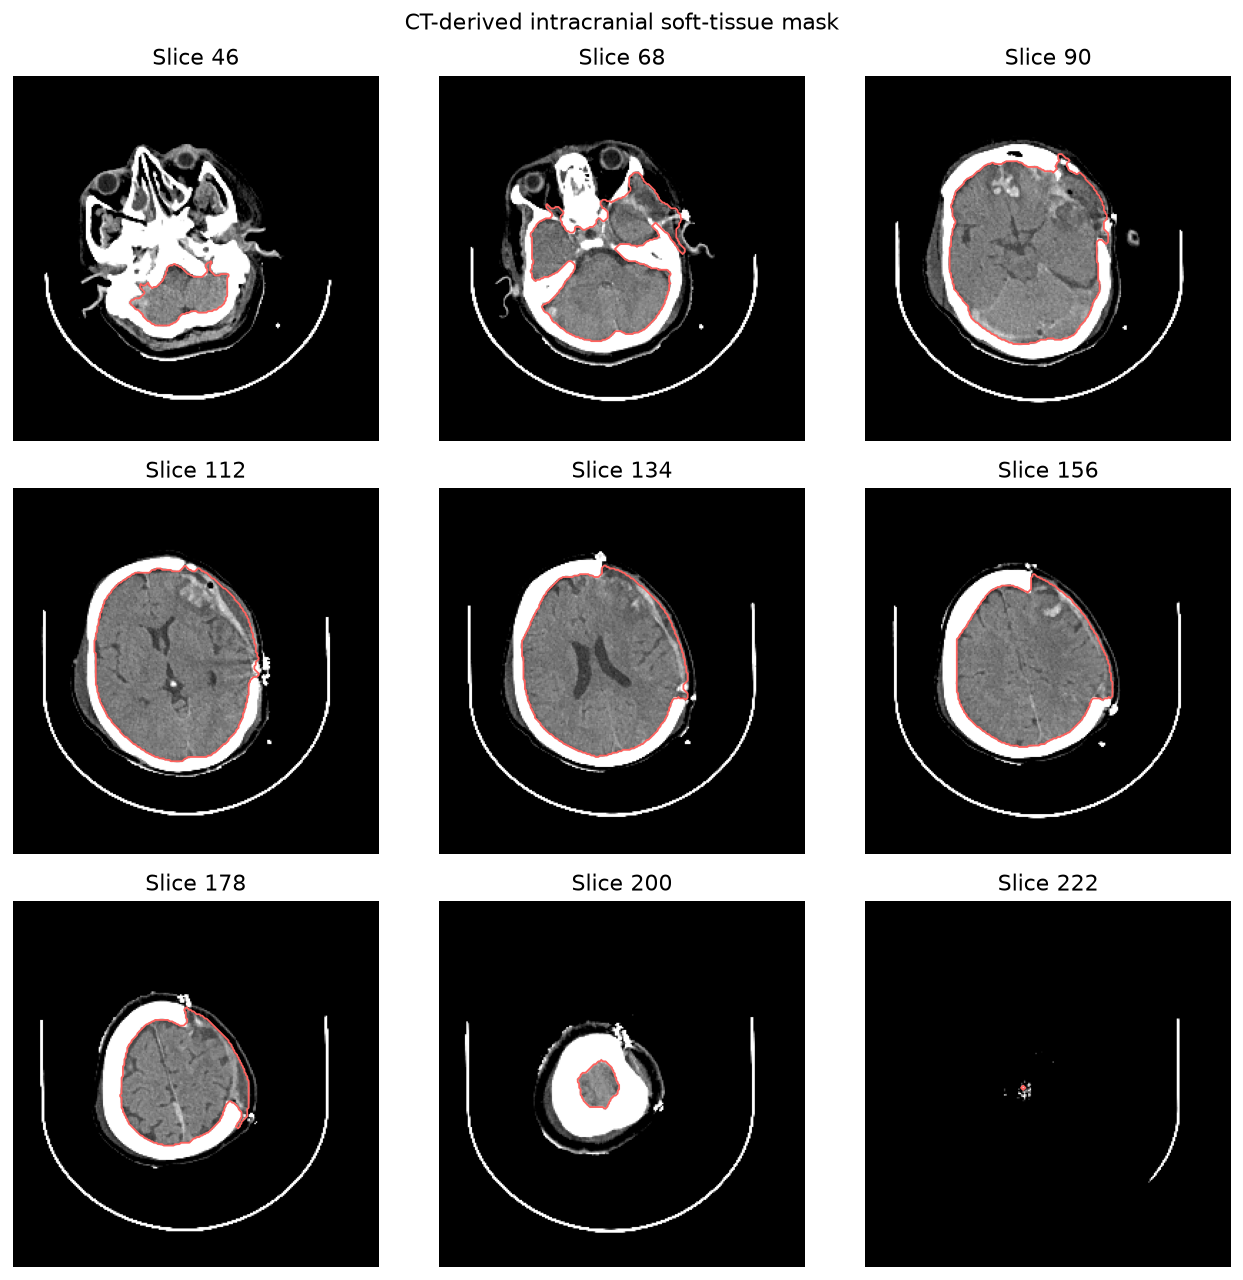

In [4]:
present = np.flatnonzero(brain_mask.reshape(len(brain_mask), -1).any(axis=1))
preview_indices = np.linspace(present[0], present[-1], 9, dtype=int)
figure, axes = plt.subplots(3, 3, figsize=(10, 10), dpi=130)
for axis, z in zip(axes.ravel(), preview_indices):
    axis.imshow(working_hu[z], cmap="gray", vmin=-20, vmax=100)
    axis.contour(brain_mask[z].astype(np.uint8), levels=[0.5], colors=["#ff625e"], linewidths=1)
    axis.set_title(f"Slice {z}")
    axis.axis("off")
figure.suptitle("CT-derived intracranial soft-tissue mask")
figure.tight_layout()
overlay_path = OUTPUT_DIR / "CASE_001_brain_mask_overlay.png"
figure.savefig(overlay_path, bbox_inches="tight")
plt.show()

## Reconstruct, smooth, display, and export the 3D surface

In [5]:
padded = np.pad(brain_mask.astype(np.uint8), 1, mode="constant")
vertices_local, faces, _normals, _values = measure.marching_cubes(
    padded, level=0.5, spacing=working_spacing, step_size=1, allow_degenerate=False
)
vertices_local -= np.asarray(working_spacing)
origin = np.asarray(datasets[0].ImagePositionPatient, dtype=float)
vertices_patient = (
    origin
    + np.outer(vertices_local[:, 0], slice_normal)
    + np.outer(vertices_local[:, 1], column_direction)
    + np.outer(vertices_local[:, 2], row_direction)
).astype(np.float32)

brain_mesh = trimesh.Trimesh(vertices=vertices_patient, faces=faces, process=True, validate=True)
brain_mesh.remove_unreferenced_vertices()
trimesh.smoothing.filter_taubin(
    brain_mesh, lamb=0.5, nu=0.525, iterations=SMOOTHING_ITERATIONS
)
brain_mesh.fix_normals(multibody=True)

ply_path = OUTPUT_DIR / "CASE_001_brain_reconstruction.ply"
stl_path = OUTPUT_DIR / "CASE_001_brain_reconstruction.stl"
glb_path = OUTPUT_DIR / "CASE_001_brain_reconstruction.glb"
html_path = OUTPUT_DIR / "CASE_001_brain_reconstruction.html"
summary_path = OUTPUT_DIR / "brain_reconstruction_summary.json"
brain_mesh.export(ply_path)
brain_mesh.export(stl_path)
scene = trimesh.Scene()
scene.add_geometry(brain_mesh.copy(), node_name="brain", geom_name="brain")
glb_path.write_bytes(scene.export(file_type="glb"))

mesh_vertices = np.asarray(brain_mesh.vertices)
mesh_faces = np.asarray(brain_mesh.faces)
shown_faces = mesh_faces
if len(shown_faces) > 180_000:
    shown_faces = shown_faces[np.linspace(0, len(shown_faces) - 1, 180_000, dtype=int)]

figure_3d = go.Figure(data=[go.Mesh3d(
    x=mesh_vertices[:, 0], y=mesh_vertices[:, 1], z=mesh_vertices[:, 2],
    i=shown_faces[:, 0], j=shown_faces[:, 1], k=shown_faces[:, 2],
    color="#d99b91", opacity=1.0, flatshading=False, hoverinfo="skip",
    lighting=dict(ambient=0.4, diffuse=0.7, specular=0.2, roughness=0.75),
)])
figure_3d.update_layout(
    title="CASE_001 — CT-derived Brain Surface",
    template="plotly_dark", width=900, height=760,
    margin=dict(l=0, r=0, t=55, b=0),
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)", yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)",
        camera=dict(eye=dict(x=1.5, y=-1.5, z=1.1)),
    ),
)
figure_3d.write_html(html_path, include_plotlyjs=True, full_html=True)
figure_3d.show()

summary = {
    "source_series": SERIES_DIR.name,
    "source_slices": len(datasets),
    "source_shape": list(volume_hu.shape),
    "voxel_spacing_mm": [slice_spacing, row_spacing, column_spacing],
    "mask_method": "CT-derived conservative intracranial soft-tissue envelope",
    "mask_volume_ml": mask_volume_ml,
    "vertices": int(len(brain_mesh.vertices)),
    "triangles": int(len(brain_mesh.faces)),
    "watertight": bool(brain_mesh.is_watertight),
    "ply_path": str(ply_path), "stl_path": str(stl_path),
    "glb_path": str(glb_path), "interactive_html_path": str(html_path),
    "overlay_path": str(overlay_path),
    "elapsed_seconds": time.time() - STARTED,
    "validated_clinical_segmentation": False,
}
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "source_series": "BRAIN_HR36F",
  "source_slices": 227,
  "source_shape": [
    227,
    512,
    512
  ],
  "voxel_spacing_mm": [
    0.75,
    0.55574609375,
    0.55574609375
  ],
  "mask_method": "CT-derived conservative intracranial soft-tissue envelope",
  "mask_volume_ml": 1224.9008845128399,
  "vertices": 111340,
  "triangles": 222684,
  "watertight": true,
  "ply_path": "F:\\csstdy\\outputs\\07_3d_reconstruction\\brain\\CASE_001_brain_reconstruction.ply",
  "stl_path": "F:\\csstdy\\outputs\\07_3d_reconstruction\\brain\\CASE_001_brain_reconstruction.stl",
  "glb_path": "F:\\csstdy\\outputs\\07_3d_reconstruction\\brain\\CASE_001_brain_reconstruction.glb",
  "interactive_html_path": "F:\\csstdy\\outputs\\07_3d_reconstruction\\brain\\CASE_001_brain_reconstruction.html",
  "overlay_path": "F:\\csstdy\\outputs\\07_3d_reconstruction\\brain\\CASE_001_brain_mask_overlay.png",
  "elapsed_seconds": 13.537567377090454,
  "validated_clinical_segmentation": false
}
